In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import files
upload = files.upload()


Saving Telco_customer_churn.xlsx to Telco_customer_churn.xlsx


In [5]:
df = pd.read_excel("Telco_customer_churn.xlsx")

In [6]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [7]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Rows: 7043
Columns: 33


Step-2: EDA Basics

In [8]:
print(df.columns.tolist())
df.info() #checks the dataset structure
df.head()
df.tail()
print("Shape of dataset:",df.shape)

['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long     

In [9]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe() #checks numerical statistics

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [12]:
df["Churn Label"].value_counts()

,count
Churn Label,
No,5174
Yes,1869


In [13]:

df["Churn Label"].value_counts(normalize=True)*100

,proportion
Churn Label,
No,73.463013
Yes,26.536987


In [14]:
df.nunique() #finds unique values

,0
CustomerID,7043
Count,1
Country,1
State,1
City,1129
Zip Code,1652
Lat Long,1652
Latitude,1652
Longitude,1651
Gender,2


STEP-3 DATA CLEANING

In [ ]:
missing = df.isnull().sum()
missing[missing > 0]

,0
Churn Reason,5174


In [15]:
df["Total Charges"].dtype
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

In [16]:
df["Total Charges"].isnull().sum()
df = df.dropna(subset=["Total Charges"])
print("Rows after cleaning:", df.shape[0])

Rows after cleaning: 7032


In [17]:
columns_to_drop = [
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Value",
    "Churn Score",
    "Churn Reason"
]

# The columns listed in 'columns_to_drop' were already removed from the DataFrame in a previous step.
# Attempting to drop them again results in a KeyError. Commenting out the redundant drop call.
# df = df.drop(columns=columns_to_drop)

In [18]:
print("Remaining columns:", df.shape[1])
print(df.columns.tolist())

Remaining columns: 33
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [19]:
print("Final shape after cleaning:", df.shape)
df.head()
df.tail()

Final shape after cleaning: (7032, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.40,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.50,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.90,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,...,Two year,Yes,Bank transfer (automatic),105.65,6844.50,No,0,38,5097,NaN


In [20]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


STEP-4 EXPLORATORY DATA ANALYSIS

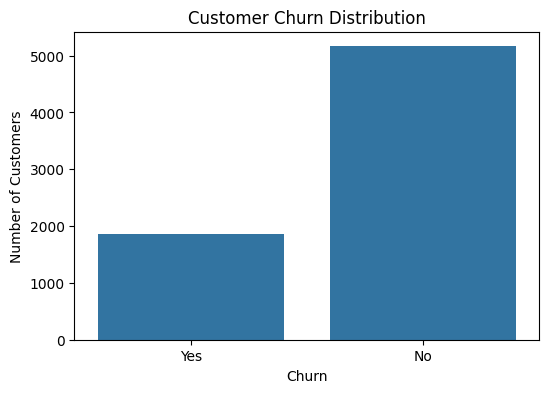

In [21]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn Label")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [22]:
df["Churn Label"].value_counts(normalize=True) * 100

,proportion
Churn Label,
No,73.421502
Yes,26.578498


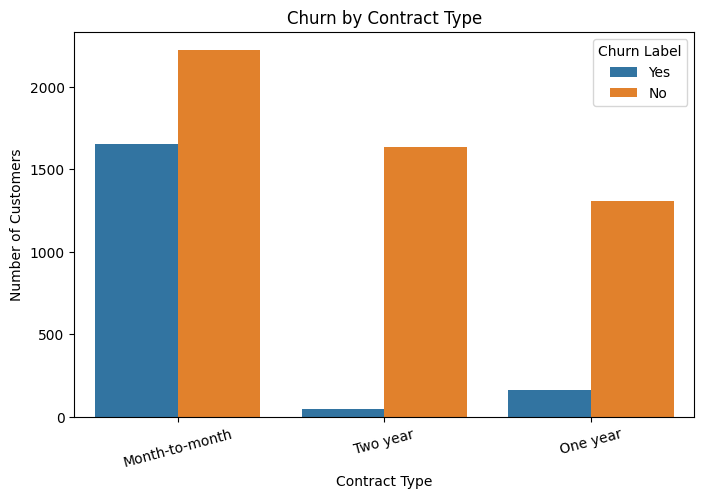

In [23]:
#churn vs contract type
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn Label")

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

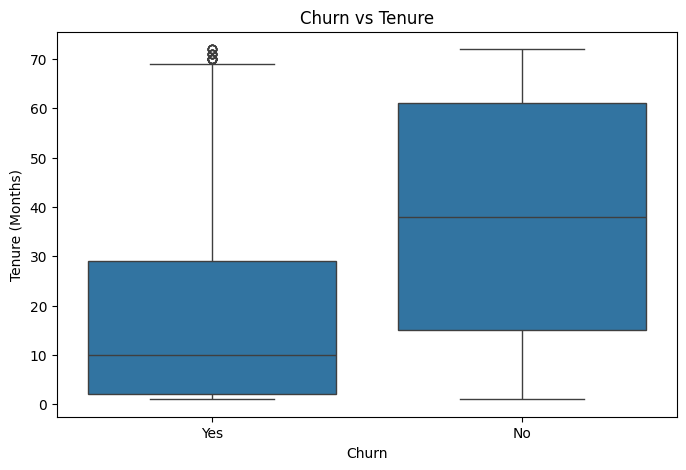

In [24]:
#churn vs tenure
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn Label", y="Tenure Months")

plt.title("Churn vs Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

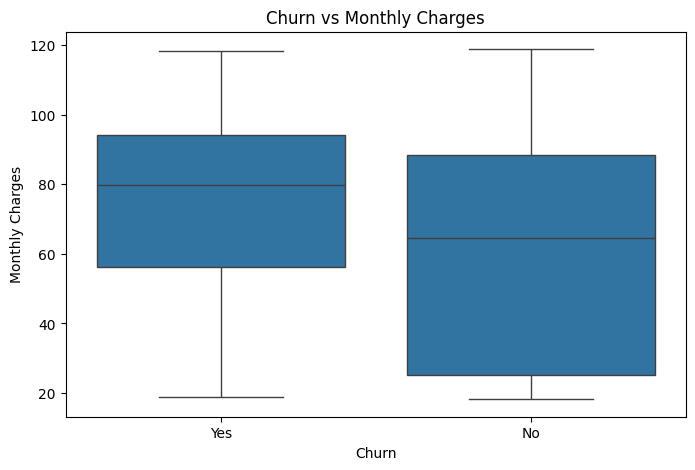

In [25]:
#churn vs monthly charges
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn Label", y="Monthly Charges")

plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

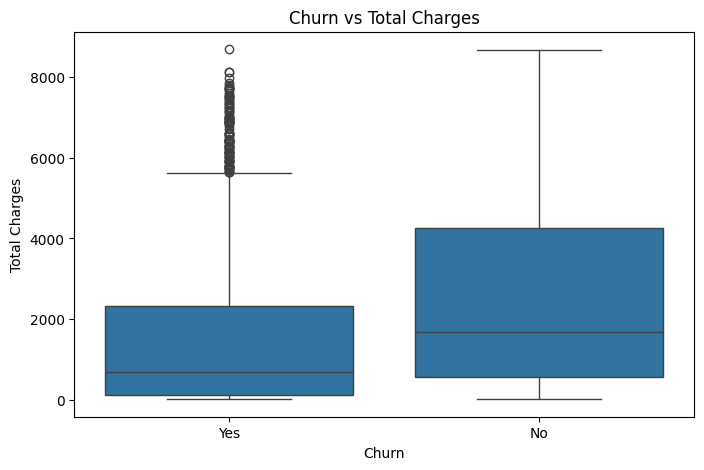

In [26]:
#churn vs total charges
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn Label", y="Total Charges")

plt.title("Churn vs Total Charges")
plt.xlabel("Churn")
plt.ylabel("Total Charges")
plt.show()

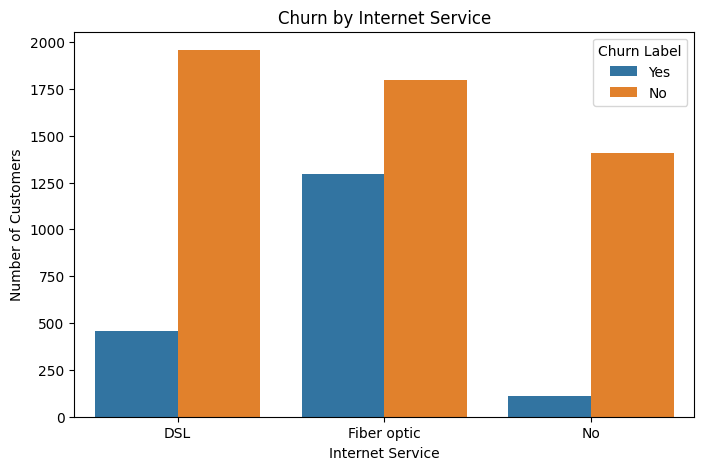

In [27]:
#churn vs internet service
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Internet Service", hue="Churn Label")

plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

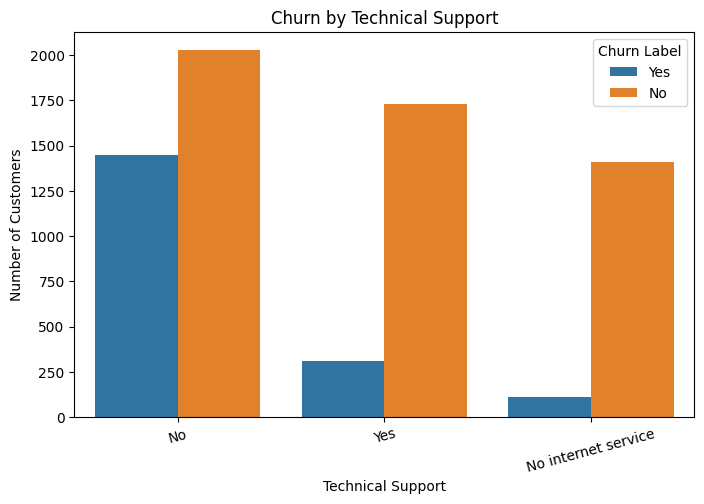

In [28]:
#churn vs tech support
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Tech Support", hue="Churn Label")

plt.title("Churn by Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

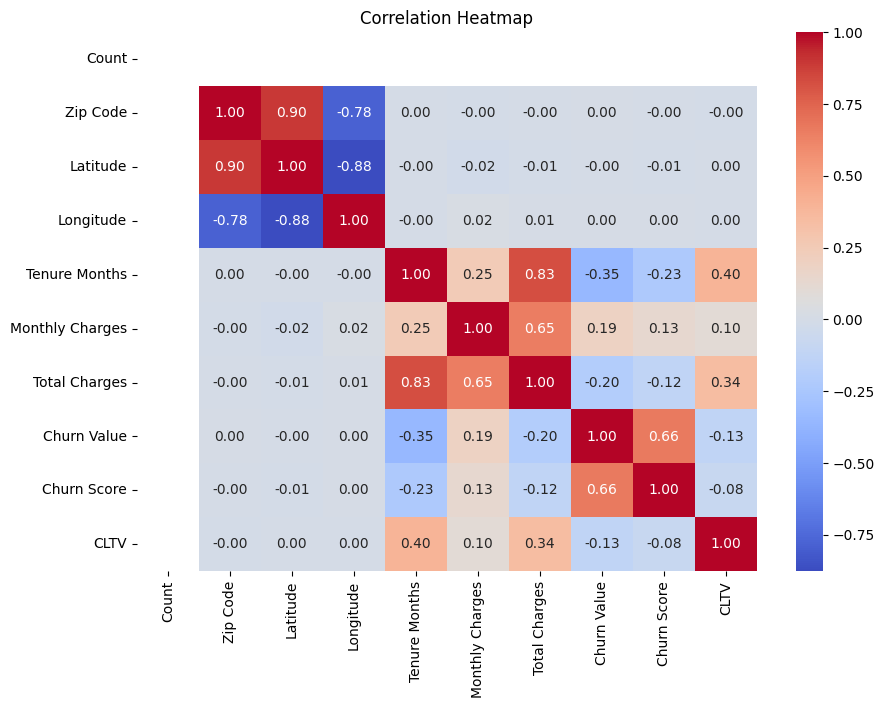

In [29]:
#correlation heatmap
numeric_cols = df.select_dtypes(include=np.number).columns

numeric_cols
plt.figure(figsize=(10, 7))

correlation = df[numeric_cols].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

STEP=5 FEATURE SELECTION

In [30]:
print(df.columns.tolist())
y = df["Churn Label"]
y.head()


['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


,Churn Label
0,Yes
1,Yes
2,Yes
3,Yes
4,Yes


In [31]:
X = df.drop(columns=["Churn Label"])
X.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,89,5340,Competitor had better devices


In [32]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7032, 32)
y shape: (7032,)


In [33]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value', 'Churn Score', 'CLTV']

Categorical Features:
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Reason']


STEP-6 DATA PREPROCESSING

In [34]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [35]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)
X_processed = preprocessor.fit_transform(X)
print("Original X shape:", X.shape)
print("Processed X shape:", X_processed.shape)

Original X shape: (7032, 32)
Processed X shape: (7032, 9889)


In [36]:
y_encoded = y.map({"No": 0, "Yes": 1})
print(y_encoded.value_counts())
print("Missing values in target:", y_encoded.isnull().sum())
print("Processed data shape:", X_processed.shape)

Churn Label
0    5163
1    1869
Name: count, dtype: int64
Missing values in target: 0
Processed data shape: (7032, 9889)


STEP-7 TRAIN-TEST SPLIT

In [37]:
from sklearn.model_selection import train_test_split

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [39]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5625, 32)
X_test : (1407, 32)
y_train: (5625,)
y_test : (1407,)


In [40]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Churn Label
0    73.422222
1    26.577778
Name: proportion, dtype: float64

Testing target distribution:
Churn Label
0    73.418621
1    26.581379
Name: proportion, dtype: float64


STEP-8 CORRECT DATA PREPROCESSING

In [41]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [42]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value', 'Churn Score', 'CLTV']

Categorical Features:
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Reason']


In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [44]:
X_train_processed = preprocessor.fit_transform(X_train)

In [45]:
X_test_processed = preprocessor.transform(X_test)

In [46]:
print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

print("\nOriginal X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

Original X_train shape: (5625, 32)
Processed X_train shape: (5625, 8476)

Original X_test shape: (1407, 32)
Processed X_test shape: (1407, 8476)


In [47]:
print("Training target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training target:
Churn Label
0    4130
1    1495
Name: count, dtype: int64

Testing target:
Churn Label
0    1033
1     374
Name: count, dtype: int64


STEP-9 BUILD THE ELASTIC NET LOGISTIC REGRESSION MODEL

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
elastic_model = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    l1_ratio=0.5,
    C=1.0,
    max_iter=2000,
    random_state=42
)

In [50]:
elastic_model.fit(X_train_processed, y_train)

LogisticRegression(l1_ratio=0.5, max_iter=2000, penalty='elasticnet',
                   random_state=42, solver='saga')

In [51]:
y_pred = elastic_model.predict(X_test_processed)
print(y_pred[:20])

[0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 0]


In [52]:
y_probability = elastic_model.predict_proba(X_test_processed)[:, 1]

In [53]:
print(y_probability[:20])

[2.55926765e-04 7.07364063e-04 3.32930027e-04 9.99248028e-01
 1.51239004e-04 9.99063592e-01 6.94076674e-04 2.60172832e-04
 9.99178259e-01 2.34372257e-04 7.51731619e-04 6.80138825e-04
 8.29601075e-04 4.21887034e-04 9.99236272e-01 9.99231321e-01
 9.99442335e-01 9.98751772e-01 3.24690221e-04 1.01362241e-04]


In [54]:
print((y_probability[:10] * 100).round(2))

[3.000e-02 7.000e-02 3.000e-02 9.992e+01 2.000e-02 9.991e+01 7.000e-02
 3.000e-02 9.992e+01 2.000e-02]


Step 10 Model Performance Evaluation

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [56]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0


In [57]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1033
           1       1.00      1.00      1.00       374

    accuracy                           1.00      1407
   macro avg       1.00      1.00      1.00      1407
weighted avg       1.00      1.00      1.00      1407



In [58]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1033    0]
 [   0  374]]


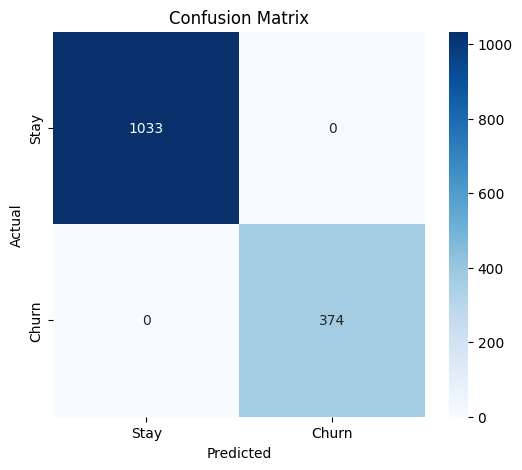

In [59]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Churn"],
    yticklabels=["Stay", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [60]:
roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 1.0


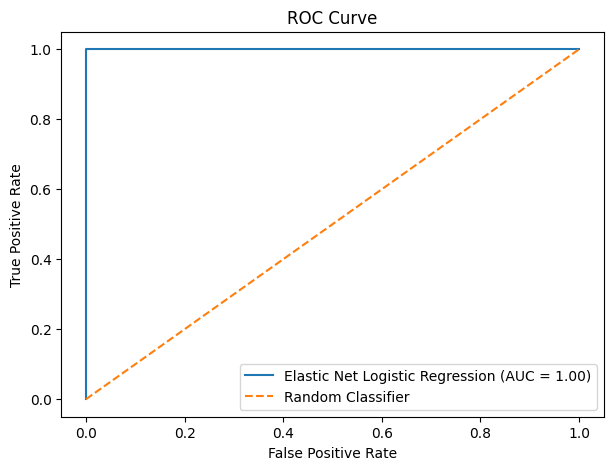

In [61]:
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Elastic Net Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Step 11 Hyperparameter Turning

In [62]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

elastic_model_tuning = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    max_iter=1000,
    random_state=42
)

param_grid = {
    "C": [0.1, 1, 10],
    "l1_ratio": [0.25, 0.5, 0.75]
}

grid_search = GridSearchCV(
    estimator=elastic_model_tuning,
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)

GridSearchCV(cv=3,
             estimator=LogisticRegression(max_iter=1000, penalty='elasticnet',
                                          random_state=42, solver='saga'),
             n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'l1_ratio': [0.25, 0.5, 0.75]},
             scoring='roc_auc')

In [63]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'C': 0.1, 'l1_ratio': 0.25}

Best Cross-Validation ROC-AUC:
1.0


In [64]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test_processed)

y_probability_tuned = best_model.predict_proba(
    X_test_processed
)[:, 1]

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
roc_auc_tuned = roc_auc_score(y_test, y_probability_tuned)

print("Tuned Model Performance")
print("------------------------")
print("Accuracy :", round(accuracy_tuned, 4))
print("Precision:", round(precision_tuned, 4))
print("Recall   :", round(recall_tuned, 4))
print("F1-Score :", round(f1_tuned, 4))
print("ROC-AUC  :", round(roc_auc_tuned, 4))

Tuned Model Performance
------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0
ROC-AUC  : 1.0


Step 12 Final Customer Churn Prediction Interface

In [66]:
y = df["Churn Label"]

X = df.drop(columns=["Churn Label"])

print("Features used for prediction:")
print(X.columns.tolist())

print("\nNumber of features:", len(X.columns))

Features used for prediction:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Number of features: 32


In [67]:
columns_to_remove = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Score",
    "Churn Reason",
    "Churn Value"
]

X = X.drop(
    columns=[col for col in columns_to_remove if col in X.columns]
)

print("Final features:")
print(X.columns.tolist())

print("\nNumber of features:", len(X.columns))

Final features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'CLTV']

Number of features: 20


In [68]:
from sklearn.model_selection import train_test_split

y_encoded = y.map({
    "No": 0,
    "Yes": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include="object"
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [70]:
from sklearn.linear_model import LogisticRegression

# Create final Elastic Net model
best_model = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    C=1.0,
    l1_ratio=0.5,
    max_iter=1000,
    random_state=42
)

# Train the final model
best_model.fit(X_train_processed, y_train)

print("Final Elastic Net model trained successfully!")

Final Elastic Net model trained successfully!


In [71]:
y_pred_tuned = best_model.predict(X_test_processed)

y_probability_tuned = best_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [72]:
def predict_customer_churn(customer_data):

    # Convert customer details into DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Apply the same preprocessing used during training
    customer_processed = preprocessor.transform(customer_df)

    # Predict churn or stay
    prediction = best_model.predict(customer_processed)[0]

    # Get churn probability
    churn_probability = best_model.predict_proba(
        customer_processed
    )[0][1]

    # Display result
    if prediction == 1:
        result = "Customer is likely to CHURN"
    else:
        result = "Customer is likely to STAY"

    print("Prediction:", result)
    print("Churn Probability:", round(churn_probability * 100, 2), "%")
    print("Stay Probability:", round((1 - churn_probability) * 100, 2), "%")

    return prediction, churn_probability

In [73]:
print("Final input features:")
for i, col in enumerate(X.columns, 1):
    print(i, ":", col)

Final input features:
1 : Gender
2 : Senior Citizen
3 : Partner
4 : Dependents
5 : Tenure Months
6 : Phone Service
7 : Multiple Lines
8 : Internet Service
9 : Online Security
10 : Online Backup
11 : Device Protection
12 : Tech Support
13 : Streaming TV
14 : Streaming Movies
15 : Contract
16 : Paperless Billing
17 : Payment Method
18 : Monthly Charges
19 : Total Charges
20 : CLTV


In [74]:
# Create a sample customer using the exact features expected by X

sample_customer = {}

for col in X.columns:
    if col in numeric_features:
        sample_customer[col] = 0
    else:
        sample_customer[col] = "No"

print(sample_customer)
predict_customer_churn(sample_customer)

{'Gender': 'No', 'Senior Citizen': 'No', 'Partner': 'No', 'Dependents': 'No', 'Tenure Months': 0, 'Phone Service': 'No', 'Multiple Lines': 'No', 'Internet Service': 'No', 'Online Security': 'No', 'Online Backup': 'No', 'Device Protection': 'No', 'Tech Support': 'No', 'Streaming TV': 'No', 'Streaming Movies': 'No', 'Contract': 'No', 'Paperless Billing': 'No', 'Payment Method': 'No', 'Monthly Charges': 0, 'Total Charges': 0, 'CLTV': 0}
Prediction: Customer is likely to STAY
Churn Probability: 32.6 %
Stay Probability: 67.4 %


(np.int64(0), np.float64(0.3259663379933509))

In [75]:
print("Categorical feature values:")
print()

for col in categorical_features:
    print(col, ":", X[col].unique())

Categorical feature values:

Gender : ['Male' 'Female']
Senior Citizen : ['No' 'Yes']
Partner : ['No' 'Yes']
Dependents : ['No' 'Yes']
Phone Service : ['Yes' 'No']
Multiple Lines : ['No' 'Yes' 'No phone service']
Internet Service : ['DSL' 'Fiber optic' 'No']
Online Security : ['Yes' 'No' 'No internet service']
Online Backup : ['Yes' 'No' 'No internet service']
Device Protection : ['No' 'Yes' 'No internet service']
Tech Support : ['No' 'Yes' 'No internet service']
Streaming TV : ['No' 'Yes' 'No internet service']
Streaming Movies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'Two year' 'One year']
Paperless Billing : ['Yes' 'No']
Payment Method : ['Mailed check' 'Electronic check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [76]:
print("\nNumeric feature ranges:")
print()

for col in numeric_features:
    print(
        col,
        "-> Min:",
        X[col].min(),
        "| Max:",
        X[col].max()
    )


Numeric feature ranges:

Tenure Months -> Min: 1 | Max: 72
Monthly Charges -> Min: 18.25 | Max: 118.75
Total Charges -> Min: 18.8 | Max: 8684.8
CLTV -> Min: 2003 | Max: 6500


In [77]:
# Create a realistic sample customer from the dataset

realistic_customer = {}

for col in X.columns:
    if col in numeric_features:
        # Use median value for numerical features
        realistic_customer[col] = X[col].median()
    else:
        # Use most common value for categorical features
        realistic_customer[col] = X[col].mode()[0]

print("Realistic Customer:")
print(realistic_customer)
# Predict churn for the realistic customer

predict_customer_churn(realistic_customer)

Realistic Customer:
{'Gender': 'Male', 'Senior Citizen': 'No', 'Partner': 'No', 'Dependents': 'No', 'Tenure Months': 29.0, 'Phone Service': 'Yes', 'Multiple Lines': 'No', 'Internet Service': 'Fiber optic', 'Online Security': 'No', 'Online Backup': 'No', 'Device Protection': 'No', 'Tech Support': 'No', 'Streaming TV': 'No', 'Streaming Movies': 'No', 'Contract': 'Month-to-month', 'Paperless Billing': 'Yes', 'Payment Method': 'Electronic check', 'Monthly Charges': 70.35, 'Total Charges': 1397.475, 'CLTV': 4527.5}
Prediction: Customer is likely to STAY
Churn Probability: 42.32 %
Stay Probability: 57.68 %


(np.int64(0), np.float64(0.4232276352430164))

In [78]:
!pip install -q gradio

In [79]:
import gradio as gr

# Prediction function
def predict_from_ui(*values):

    customer_data = {}

    for col, value in zip(X.columns, values):
        customer_data[col] = value

    prediction, probability = predict_customer_churn(customer_data)

    if prediction == 1:
        result = "🔴 CUSTOMER IS LIKELY TO CHURN"
    else:
        result = "🟢 CUSTOMER IS LIKELY TO STAY"

    return (
        result,
        f"{probability * 100:.2f}%"
    )


# Create input components
input_components = []

for col in X.columns:

    if col in categorical_features:

        component = gr.Dropdown(
            choices=sorted(
                X[col].dropna().unique().tolist()
            ),
            label=col,
            interactive=True
        )

    else:

        component = gr.Number(
            label=col,
            value=float(X[col].median()),
            interactive=True
        )

    input_components.append(component)


# Create professional interface
demo = gr.Interface(
    fn=predict_from_ui,

    inputs=input_components,

    outputs=[
        gr.Textbox(
            label="Prediction",
            lines=1
        ),

        gr.Textbox(
            label="Churn Probability",
            lines=1
        )
    ],

    title="📊 Customer Churn Prediction System",

    description="""
    <h3>Elastic Net Regularized Logistic Regression</h3>
    Enter the customer details below to predict whether the customer
    is likely to churn or stay.
    """,

    submit_btn="🔍 Predict Churn",
    clear_btn="🔄 Clear",

    theme=gr.themes.Soft()
)

demo.launch()

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0902ceafca1034ae80.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Final Model Evaluattion and Results

In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Final predictions
y_pred_final = best_model.predict(X_test_processed)

# Churn probabilities
y_prob_final = best_model.predict_proba(X_test_processed)[:, 1]

# Calculate metrics
accuracy_final = accuracy_score(y_test, y_pred_final)
precision_final = precision_score(y_test, y_pred_final)
recall_final = recall_score(y_test, y_pred_final)
f1_final = f1_score(y_test, y_pred_final)
roc_auc_final = roc_auc_score(y_test, y_prob_final)

print("===== FINAL MODEL PERFORMANCE =====")
print("Accuracy  :", round(accuracy_final, 4))
print("Precision :", round(precision_final, 4))
print("Recall    :", round(recall_final, 4))
print("F1-Score  :", round(f1_final, 4))
print("ROC-AUC   :", round(roc_auc_final, 4))

===== FINAL MODEL PERFORMANCE =====
Accuracy  : 0.8074
Precision : 0.6467
Recall    : 0.607
F1-Score  : 0.6262
ROC-AUC   : 0.8433


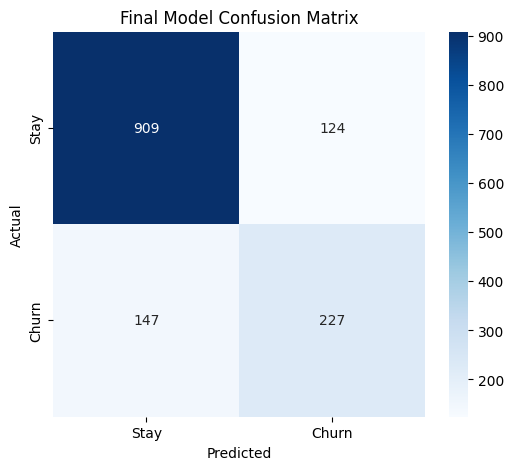

In [81]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_final = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Churn"],
    yticklabels=["Stay", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Model Confusion Matrix")

plt.show()

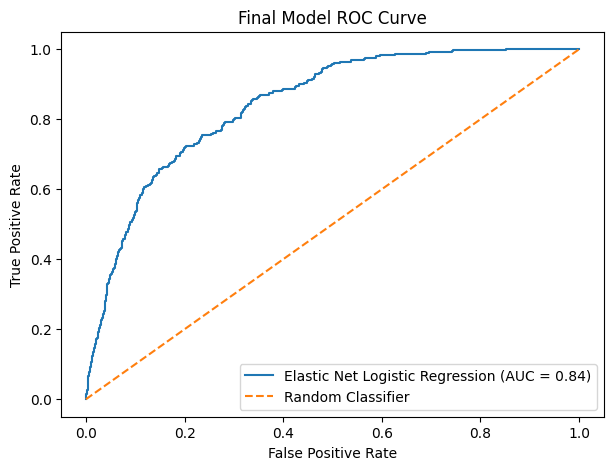

In [82]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_final
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Elastic Net Logistic Regression (AUC = {roc_auc_final:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Model ROC Curve")
plt.legend()

plt.show()

In [83]:
from sklearn.metrics import classification_report

print("===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Stay", "Churn"]
    )
)

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Stay       0.86      0.88      0.87      1033
       Churn       0.65      0.61      0.63       374

    accuracy                           0.81      1407
   macro avg       0.75      0.74      0.75      1407
weighted avg       0.80      0.81      0.81      1407



In [84]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_final,
        precision_final,
        recall_final,
        f1_final,
        roc_auc_final
    ]
})

results["Score"] = results["Score"].round(4)

print(results)

      Metric   Score
0   Accuracy  0.8074
1  Precision  0.6467
2     Recall  0.6070
3   F1-Score  0.6262
4    ROC-AUC  0.8433


Step 14 Feature Importance / Churn Factors

In [85]:
# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("\nFirst 20 features:")
print(feature_names[:20])

Number of processed features: 47

First 20 features:
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'num__CLTV' 'cat__Gender_Female' 'cat__Gender_Male'
 'cat__Senior Citizen_No' 'cat__Senior Citizen_Yes' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__Phone Service_No' 'cat__Phone Service_Yes' 'cat__Multiple Lines_No'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_DSL' 'cat__Internet Service_Fiber optic'
 'cat__Internet Service_No']


In [86]:
# Get model coefficients

coefficients = best_model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("Top 20 influential features:")
print(feature_importance.head(20))

Top 20 influential features:
                                 Feature  Coefficient  Absolute_Coefficient
0                     num__Tenure Months    -1.365494              1.365494
11                   cat__Dependents_Yes    -0.829567              0.829567
38          cat__Contract_Month-to-month     0.801526              0.801526
10                    cat__Dependents_No     0.800923              0.800923
18     cat__Internet Service_Fiber optic     0.667669              0.667669
2                     num__Total Charges     0.625984              0.625984
40                cat__Contract_Two year    -0.554206              0.554206
20               cat__Online Security_No     0.403995              0.403995
29                  cat__Tech Support_No     0.388184              0.388184
14                cat__Multiple Lines_No    -0.320010              0.320010
45  cat__Payment Method_Electronic check     0.305230              0.305230
34                 cat__Streaming TV_Yes     0.278390      

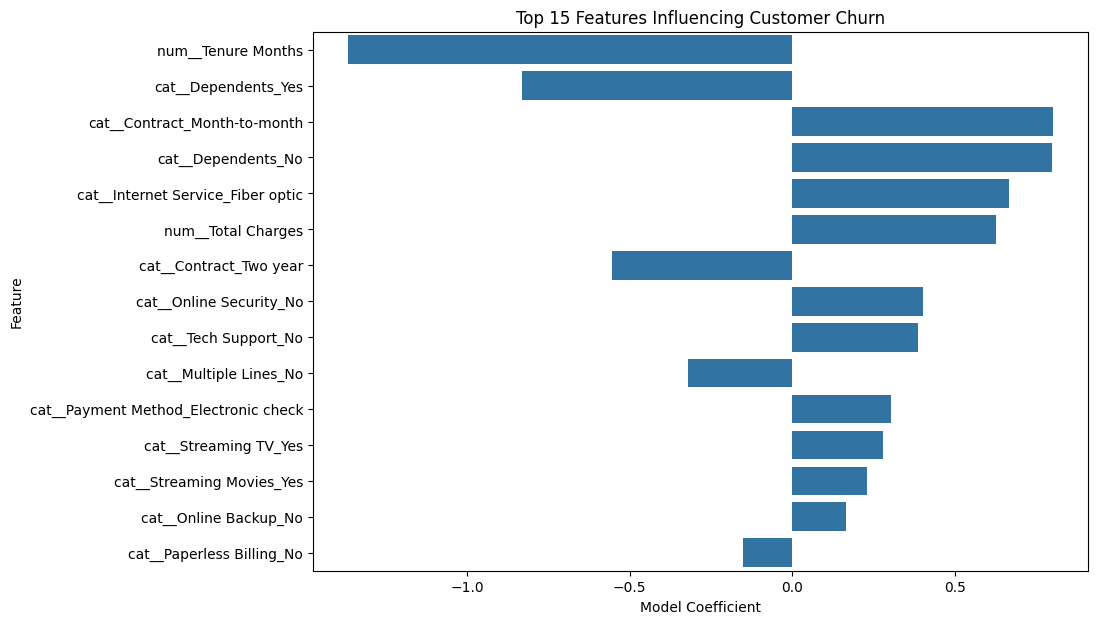

In [87]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Model Coefficient")
plt.ylabel("Feature")

plt.show()

In [88]:
positive_features = feature_importance[
    feature_importance["Coefficient"] > 0
].head(10)

negative_features = feature_importance[
    feature_importance["Coefficient"] < 0
].head(10)

print("Features associated with higher churn:")
print(
    positive_features[
        ["Feature", "Coefficient"]
    ]
)

print("\nFeatures associated with lower churn:")
print(
    negative_features[
        ["Feature", "Coefficient"]
    ]
)

Features associated with higher churn:
                                 Feature  Coefficient
38          cat__Contract_Month-to-month     0.801526
10                    cat__Dependents_No     0.800923
18     cat__Internet Service_Fiber optic     0.667669
2                     num__Total Charges     0.625984
20               cat__Online Security_No     0.403995
29                  cat__Tech Support_No     0.388184
45  cat__Payment Method_Electronic check     0.305230
34                 cat__Streaming TV_Yes     0.278390
37             cat__Streaming Movies_Yes     0.231886
23                 cat__Online Backup_No     0.164368

Features associated with lower churn:
                                          Feature  Coefficient
0                              num__Tenure Months    -1.365494
11                            cat__Dependents_Yes    -0.829567
40                         cat__Contract_Two year    -0.554206
14                         cat__Multiple Lines_No    -0.320010
41           

Step 15 Complete Pipeline

In [89]:
print("""
========== CUSTOMER CHURN PREDICTION PIPELINE ==========

1. Load Telco Customer Churn Dataset
                    ↓
2. Understand the Dataset
                    ↓
3. Clean the Data
                    ↓
4. Exploratory Data Analysis
                    ↓
5. Select Features and Target
                    ↓
6. Encode Target Variable
                    ↓
7. Train-Test Split
                    ↓
8. Feature Scaling + One-Hot Encoding
                    ↓
9. Elastic Net Logistic Regression
                    ↓
10. Model Evaluation
                    ↓
11. Hyperparameter Tuning
                    ↓
12. Final Prediction Interface
                    ↓
13. Final Model Evaluation
                    ↓
14. Feature Importance Analysis
                    ↓
15. Final Churn Prediction
                    ↓
       CHURN / STAY
=========================================================
""")


========== CUSTOMER CHURN PREDICTION PIPELINE ==========

1. Load Telco Customer Churn Dataset
                    ↓
2. Understand the Dataset
                    ↓
3. Clean the Data
                    ↓
4. Exploratory Data Analysis
                    ↓
5. Select Features and Target
                    ↓
6. Encode Target Variable
                    ↓
7. Train-Test Split
                    ↓
8. Feature Scaling + One-Hot Encoding
                    ↓
9. Elastic Net Logistic Regression
                    ↓
10. Model Evaluation
                    ↓
11. Hyperparameter Tuning
                    ↓
12. Final Prediction Interface
                    ↓
13. Final Model Evaluation
                    ↓
14. Feature Importance Analysis
                    ↓
15. Final Churn Prediction
                    ↓
       CHURN / STAY



In [120]:
import joblib
import os

# Save the trained model
joblib.dump(best_model, "elastic_net_churn_model.pkl")

# Save the fitted preprocessor
joblib.dump(preprocessor, "churn_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

print("Model exists:",
      os.path.exists("elastic_net_churn_model.pkl"))

print("Preprocessor exists:",
      os.path.exists("churn_preprocessor.pkl"))

Model and preprocessor saved successfully!
Model exists: True
Preprocessor exists: True
